1. **Nome(s):** Leonardo Silveira Kiepper

2. **Matrícula(s):** 2026140417

3. **E-mail(s) institucional(is):** leonardo.kiepper@edu.ufes.br

3. **Curso(s):** Doutorado em Ciência da Computação

4. **Link do seu Colab com suas soluções (para que o professor possa acessar e rodar o código):** https://colab.research.google.com/github/LeoKiepper/Ciencia-de-Dados/blob/main/trabalho1/T1_leonardo_kiepper.ipynb


In [100]:
%pip install itables
%pip install nltk
%pip install unidecode
%pip install scikit-learn
%pip install langdetect
%pip install jinja2


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jinja2]
Note: you may need to restart the kernel to use updated packages.


`book_id` não contribuirá para exprimir uma relação com `genre`, pois é apenas um indexador no *dataset*, e não ‘promete’ nenhuma relação com o conteúdo do livro. Qualquer relação encontrada seria expúria, então será usado como *index* do DataFrame.

In [155]:
#@title Importa o dataset completo
import os
import pandas as pd
from langdetect import detect, DetectorFactory, LangDetectException
from itables import show

livros = pd.read_csv('goodreads_books.csv').set_index('book_id')

# Descarta textos que não estão em inglês
DetectorFactory.seed = 0 
def idioma(texto):
    if not isinstance(texto, str) or not texto.strip():
        return None
    try:
        return detect(texto)
    except LangDetectException:
        return None

ARQ_IDIOMA = 'idiomas.csv'
if 'idioma' not in livros.columns:
    if os.path.exists(ARQ_IDIOMA):
        idiomas = pd.read_csv(ARQ_IDIOMA, index_col='book_id')['idioma']
        livros['idioma'] = idiomas.reindex(livros.index)
    else:
        livros['idioma'] = livros['description'].apply(idioma)
        livros['idioma'].to_csv(ARQ_IDIOMA)


livros['idioma'] = livros['description'].apply(idioma)
def descreve_dataset(df: pd.DataFrame):
    print(f"Número de livros: {len(df)}")
    print('')
    print(f"Quantos NaN em cada coluna: \n{df.isna().sum()}")
    print('')
    print("Autores distintos:", df['author'].nunique())
    if 'idioma' in df.columns: 
        print('')
        print('Quantidade de livros por idioma')   
        print(livros['idioma'].value_counts())
    # print(livros['author'].value_counts())    
descreve_dataset(livros)

livros = livros[livros['idioma'] == 'en']
show(livros.loc[:,livros.columns!='description'])

KeyboardInterrupt: 

In [ ]:
#@title Amostra uma fatia do dataset
import numpy as np

# A título de ensaio, pega uma fatia pequena, e fixa a semente com random_state
# semente = 2003343720
semente = np.random.randint(0, 2**31)
df=livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
descreve_dataset(df)
show(df)

Aqui pode ser relevante analisar o titulo e a descrição, pois o titulo e a descrição carregam informações diferentes, e tem utilidades diferentes. A descrição é o que vende o livro para um leitor em potencial, e o titulo é o gancho que puxa a atenção; objetivos diferentes, que pedem estratégias e estilos de escrita diferentes.

Sobre pré-processamento textual, do material de aula:
>É uma boa prática seguir, ao menos, os seguintes passos:
>1. Dividir o texto em *tokens*
>2. Converter o texto para letras minúsculas
>3. Remover símbolos de pontuação de cada *token*
>4. Converter caracteres especiais (passo discutível e necessidade deve ser analisada)
>5. Remover *tokens* que não são palavras
>6. Remover *tokens* que são *stop words*


In [ ]:
#@title Tokeniza o dataset
import string
import pandas as pd
import nltk
from nltk import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from itables import show

nltk.download('punkt_tab')
nltk.download('stopwords')

def preprocessamento(df: pd.Series):
    # 1. Dividir o texto em tokens
    tokens = word_tokenize(df)  
    # tokens = sent_tokenize(df)

    # 2. Converter o texto para letras minúsculas
    tokens = [w.lower() for w in tokens]

    # 3. Remover símbolos de pontuação de cada token
    table = str.maketrans('', '', string.punctuation)
    tokens = [w.translate(table) for w in tokens]

    # 4. Converter caracteres especiais
    # tokens = [unidecode.unidecode(w).lower() for w in tokens]

    # 5. Remover tokens que não são palavras
    words = [word for word in tokens if word.isalpha()]

    # 6. Remover tokens que são stop words
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if not word in stop_words]
    
    # Stemming
    # porter = PorterStemmer()
    # stemmed = [porter.stem(word) for word in words]
    # words = stemmed
    
    return words

show(df['description'].apply(preprocessamento))


In [ ]:
#@title Calcula TF-IDF sobre as matrizes de tokens
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from itables import show

def calculaX(x: pd.Series):
    vectorizer = TfidfVectorizer(analyzer=preprocessamento)
    X = vectorizer.fit_transform(x)
    return pd.DataFrame.sparse.from_spmatrix(
        X,
        index=x.index,
        columns=vectorizer.get_feature_names_out()
    ).astype(pd.SparseDtype('float64', 0))


X_desc = calculaX(df['description'])
show(X_desc)

X_title = calculaX(df['title'])
show(X_title)

def encontra_token_max(X: pd.DataFrame) -> str:
    return X.max(axis=0).idxmax()
print(f"Tamanho do corpus, descrição: {len(X_desc.columns)}.")
print(f"\tTF-IDF máximo, descrição: {X_desc.max().max()}")
print(f"\ttoken com TF-IDF máximo: {encontra_token_max(X_desc)}")
print(f"Tamanho do corpus, título: {len(X_title.columns)}.")
print(f"\tTF-IDF máximo, título: {X_title.max().max()}")
print(f"\ttoken com TF-IDF máximo: {encontra_token_max(X_title)}")

A estratégia de vetorizar pelo processo codificado nas células acima não é aplicável a todas as colunas do *dataset*. Por exemplo, a coluna Autor pode ser vista como um dado categórico, e precisaria de um tratamento diferente. 

As células acimas, responsáveis por vetorizar a descrição e o título, foram rodadas para o *dataset* completo para saber a dimensão máxima da matriz X:

>```
>Tamanho do corpus, descrição: 112003.
>	TF-IDF máximo, descrição: 0.9311781254312337
>	token com TF-IDF máximo: waldo
>Tamanho do corpus, título: 19157.
>	TF-IDF máximo, título: 1.0
>	token com TF-IDF máximo: abandon
>```

Em comparação, as demais características presentes no *dataset*, descontando o `genre`, `description`, `title` e `book_id`, somam 5 dimensões à análise sobre o *dataset*. Dito isso, não faz sentido sujeitar essas dimensões ao algorítimo de PCA, junto com as matrizes `X`. O ganho seria comparativamente desprezível, e poderia haver perda de informação desproporcional.

Portanto, deseja-se fazer uma redução de dimensionalidade sobre `X_desc` e `X_title` separadamente. Desta forma, além de reduzir a dimensão tão somente sobre o que inviabiliza a análise, o algorítimo trabalha sobre dados de mesma natureza — e automaticamente na mesma escala — e assim, a perda de intuição sobre as grandezas dos dados é menos problemática.

Deseja-se fazer o PCA aplicando SVD truncado sobre cada matriz X, produzindo um resultado gantidamente equivalente (https://scikit-learn.org/stable/modules/decomposition.html#lsa). Para selecionar o número de componentes do PCA (aqui, implementado com SVD), é necessário seguir um procedimento sistemático, considerando o erro de aproximação, análogo a como é feito com PCA

Sobre o método geral para determinação do $k$:

>##### Do material de aula sobre PCA:
>**Entrada:**
>1. Matriz de dados $\mathbf{X} \in \mathbb{R}^{n \times d}$
>2. $0 \le \alpha \le 1$, fração da variância total a ser considerada 
><br><br>
>
>**Passos:**
>
>3. $\mathbf{Z} \leftarrow$ matriz $\mathbf{X}$ após centralização/pré-processamento
>4. $\Sigma \leftarrow \frac{\mathbf{Z}^T\mathbf{Z}}{n}$
>5. $\lambda_1, \dots, \lambda_d \leftarrow$ autovalores de $\Sigma$ ordenados decrescentemente
>6. $\mathbf{u}_1, \dots, \mathbf{u}_d \leftarrow$ autovetores de $\Sigma$ ($\mathbf{u_i}$ está associado a $\lambda_i$)
>7. $f(k) \leftarrow \frac{\sum_{i=1}^k\lambda_i}{\sum_{i=1}^d\lambda_i}$, para $k = 1, \dots, d$
>8. Escolha o menor $k$ tal que $f(k) \ge \alpha$
>9. $\mathbf{U}_k \leftarrow$ matriz cujas colunas são $\mathbf{u}_1, \dots, \mathbf{u}_k$
><br>
>
>**Saída:**
>
>10. Retorne $\mathbf{Z}\mathbf{U}_k$

SVD entrega os valores $\sigma_k$ já ordenados, e a matriz aproximada de *rank* $k$, $\mathbf{X}_\text{k}$, é dada por: $$ \mathbf{X}_k = \mathbf{U}_k\mathbf{S}_k\mathbf{V}_k^T.$$

Dito isso, escolher o $k$ significa trazer a norma de Frobenius $$\Vert\mathbf{X} - \mathbf{X}_k\Vert_F = \sqrt{\sum_{i=k+1}^r\sigma^2_i}.$$ para um patamar aceitável, definido em função do $\alpha$, descrito acima


# Verificação PCA

Deseja-se aplicar O SVD truncado sobre a matriz esparsa, o que permite tratar matrizes grandes em tempo de processamento razoável. A título de teste de sanidade, é fixada uma amostra pequena do dataset completo, que é sujeitada ao SVD truncado, SVD completo e PCA, e os resultados são comparados para demonstrar que são equivalentes, como esperado. Depois, nos três algorítimos, o procedimento de seleção do $k$ é feito para um $alpha$ pré-selecionado, e novamente, as matrizes reduzidas são comparadas.

In [ ]:
#@title Funções auxiliares de cálculo
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import norm as spnorm
from sklearn.preprocessing import StandardScaler

def _como_matriz(X):
    """Normaliza a entrada. Devolve (M, indice): M é CSR se a entrada for esparsa,
    ndarray se for densa; indice é o índice do DataFrame, ou None."""
    if isinstance(X, pd.DataFrame):
        idx = X.index
        try:
            M = sp.csr_matrix(X.sparse.to_coo(), dtype=np.float64)   # DataFrame esparso
        except AttributeError:
            M = X.to_numpy(dtype=np.float64)                         # DataFrame denso
    elif sp.issparse(X):
        idx, M = None, sp.csr_matrix(X, dtype=np.float64)
    else:
        idx, M = None, np.asarray(X, dtype=np.float64)
    return M, idx

def _norma2(M):
    """||M||_F^2, para esparsa ou densa."""
    return float(spnorm(M) ** 2) if sp.issparse(M) else float(np.linalg.norm(M) ** 2)

def _densa(M):
    return M.toarray() if sp.issparse(M) else M

def padroniza(M):
    """Densifica e aplica StandardScaler: média 0 e desvio 1 por coluna."""
    return StandardScaler(with_mean=True, with_std=True).fit_transform(_densa(M))

def seleciona_k(f_acum, alpha):
    """Menor k com fração acumulada de variância explicada >= alpha. None se não atingido."""
    atinge = np.flatnonzero(f_acum >= alpha)
    return int(atinge[0]) + 1 if len(atinge) else None


def _saida(Xk, idx):
    cols = [f'c{i+1}' for i in range(Xk.shape[1])]
    return pd.DataFrame(Xk, index=idx, columns=cols) if idx is not None else Xk


In [ ]:
#@title Métodos de redução: reduz_dim(X, alpha) -> (X_k, k)
import numpy as np
import scipy.sparse as sp
import scipy.linalg
from sklearn.decomposition import TruncatedSVD, PCA

def PCA_completo(X, alpha, info=None):
    """PCA sobre a matriz padronizada (densa). Devolve (Z U_k, k)."""
    M, idx = _como_matriz(X)
    Z = padroniza(M)
    pca = PCA(svd_solver='full').fit(Z)
    s = pca.singular_values_
    f_acum = np.cumsum(pca.explained_variance_ratio_)
    k = seleciona_k(f_acum, alpha)
    Xk = pca.transform(Z)[:, :k]
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(Z), entrada='Z (densa, padronizada)')
    return _saida(Xk, idx), k

def SVD_completo(X, alpha, info=None):
    """SVD completo sobre a matriz padronizada (densa). Devolve (U_k S_k, k)."""
    M, idx = _como_matriz(X)
    Z = padroniza(M)
    u, s, _ = scipy.linalg.svd(Z, full_matrices=False, lapack_driver='gesvd')
    f_acum = np.cumsum(s ** 2) / np.sum(s ** 2)
    k = seleciona_k(f_acum, alpha)
    Xk = u[:, :k] * s[:k]
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(Z), entrada='Z (densa, padronizada)')
    return _saida(Xk, idx), k

def SVD_truncado(X, alpha, k0=64, kmax=None, algorithm='arpack', random_state=0, info=None):
    """SVD truncado sobre a matriz como foi passada (esparsa ou densa). Devolve (U_k S_k, k).
    Ajusta k0 componentes e dobra até atingir alpha, limitado a kmax.
    algorithm='arpack' é exato (Lanczos); 'randomized' é mais rápido, mas aproximado."""
    M, idx = _como_matriz(X)
    limite = min(M.shape) - 1 if kmax is None else min(kmax, min(M.shape) - 1)
    k_fit = min(k0, limite)
    while True:
        svd = TruncatedSVD(n_components=k_fit, algorithm=algorithm, random_state=random_state).fit(M)
        s = svd.singular_values_
        f_acum = np.cumsum(svd.explained_variance_ratio_)
        k = seleciona_k(f_acum, alpha)
        if k is not None or k_fit >= limite:
            break
        k_fit = min(2 * k_fit, limite)
    if k is None:
        print(f'[SVD_truncado] alpha={alpha} não atingido com kmax={limite}; usando k={k_fit}')
        k = k_fit
    Xk = svd.transform(M)[:, :k]
    tipo = 'esparsa' if sp.issparse(M) else 'densa'
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(M), entrada=f'como passada ({tipo})')
    return _saida(Xk, idx), k

In [ ]:
#@title Suite de verificação
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Fatia de verificação: semente e tamanho próprios, independentes do restante do notebook
SEMENTE_VER = 2003343720
N_VER = 1000
REPO_RAW = 'https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/'
ARQ_VER = f'amostra_n{N_VER}_seed{SEMENTE_VER}.csv'

def carrega_fatia():
    """Carrega a fatia de verificação: arquivo local -> GitHub -> gera de `livros` e salva."""
    if os.path.exists(ARQ_VER):
        return pd.read_csv(ARQ_VER, index_col='book_id')
    try:
        return pd.read_csv(REPO_RAW + ARQ_VER, index_col='book_id')
    except Exception:
        pass
    fatia = livros.sample(n=N_VER, random_state=SEMENTE_VER).drop(columns=['idioma'], errors='ignore')
    fatia.to_csv(ARQ_VER)
    print(f'Fatia gerada e salva em {ARQ_VER}')
    return fatia

DF_VER = carrega_fatia()
X_VER = calculaX(DF_VER['description'])
print(f'Fatia de verificação: {len(DF_VER)} livros, X_VER {X_VER.shape}')

def _plota_espectro(ax1, ax2, s, f_acum, alpha, k, rotulo):
    ks = np.arange(1, len(s) + 1)

    ax1.plot(ks, s, lw=1.5)
    ax1.axvline(k, ls='--', color='gray', lw=1, label=fr'$k_\alpha$ = {k}')
    ax1.set_ylim(bottom=0)
    ax1.set_xlabel(r'$k$'); ax1.set_ylabel(r'$\sigma_k$')
    ax1.set_title(f'{rotulo}: valores singulares')
    ax1.legend(frameon=False)

    ax2.plot(ks, f_acum, lw=1.5)
    ax2.axhline(alpha, ls='--', color='tab:red', lw=1, label=fr'$\alpha$ = {alpha:.2f}')
    ax2.axvline(k, ls='--', color='gray', lw=1, label=fr'$k_\alpha$ = {k}')
    ax2.set_ylim(0, 1)
    ax2.set_xlabel(r'$k$'); ax2.set_ylabel('Fração da variância explicada')
    ax2.set_title(f'{rotulo}: variância explicada')
    ax2.legend(frameon=False)

def _plota_diferencas(res):
    """Mapa de calor de max|σᵢ − σⱼ| entre métodos: só o triângulo superior, escala log."""
    nomes = list(res)
    n = len(nomes)
    D = np.full((n, n), np.nan)         # NaN não é desenhado pelo imshow
    for i in range(n):
        for j in range(i + 1, n):
            sa, sb = res[nomes[i]]['s'], res[nomes[j]]['s']
            m = min(len(sa), len(sb))
            D[i, j] = max(np.abs(sa[:m] - sb[:m]).max(), 1e-16)

    fig, ax = plt.subplots(figsize=(1.7 * n + 2.5, 1.1 * n + 1.5))
    im = ax.imshow(D, cmap='Blues', norm=LogNorm(vmin=1e-14, vmax=max(np.nanmax(D), 1e-13)))
    ax.set_xticks(range(n), nomes, rotation=30, ha='left')
    ax.set_yticks(range(n), nomes)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for spine in ax.spines.values(): spine.set_visible(False)
    for i in range(n):
        for j in range(i + 1, n):
            cor = 'white' if D[i, j] > 1e-3 else 'black'
            ax.text(j, i, f'{D[i, j]:.1e}', ha='center', va='center', color=cor, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8, label=r'max $|\sigma_i - \sigma_j|$ (log)')
    ax.set_title('Diferença máxima entre espectros', pad=40)
    fig.tight_layout()

def verifica(metodos, alpha):
    """Roda cada reduz_dim(X_VER, alpha), plota os gráficos 1 e 2 lado a lado por método,
    o resumo em tabela e o mapa de diferenças. `metodos`: funções ou tuplas (nome, função)."""
    res = {}
    for m in metodos:
        nome, f = m if isinstance(m, tuple) else (m.__name__, m)
        info = {}
        Xk, k = f(X_VER, alpha, info=info)
        res[nome] = dict(k=k, shape=Xk.shape, **info)

    # Gráficos 1 e 2: uma linha por método, duas colunas
    fig, axes = plt.subplots(len(res), 2, figsize=(12, 3.4 * len(res)), squeeze=False)
    for (nome, r), (ax1, ax2) in zip(res.items(), axes):
        _plota_espectro(ax1, ax2, r['s'], r['f_acum'], alpha, r['k'], nome)
    fig.tight_layout()
    plt.show()

    # Bloco 1: resumo por método
    resumo = pd.DataFrame({
        nome: {'k': r['k'], 'X_k (linhas, colunas)': r['shape'], 'σ calculados': len(r['s']),
               '||entrada||_F²': round(r['Anorm2'], 1), 'entrada': r['entrada']}
        for nome, r in res.items()
    }).T
    resumo.index.name = f'alpha = {alpha}'
    display(resumo)

    # Bloco 2: mapa de diferenças
    _plota_diferencas(res)
    plt.show()
    return res


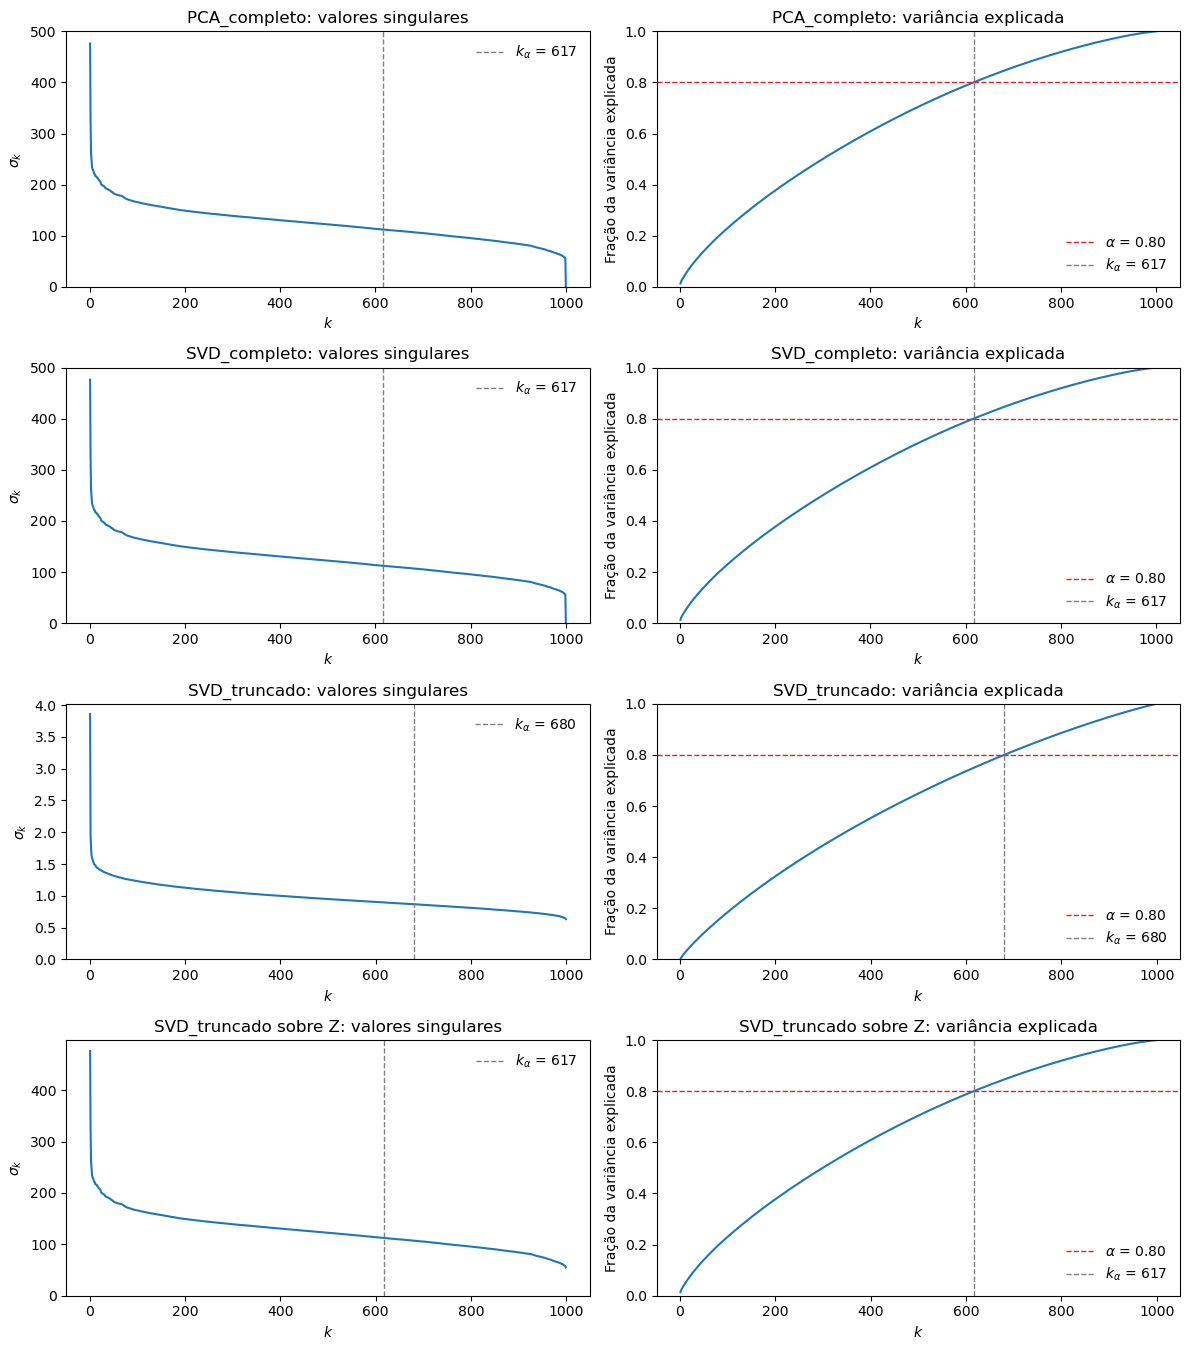

,k,"X_k (linhas, colunas)",σ calculados,||entrada||_F²,entrada
alpha = 0.8,,,,,
PCA_completo,617,"(1000, 617)",1000,16790000.0,"Z (densa, padronizada)"
SVD_completo,617,"(1000, 617)",1000,16790000.0,"Z (densa, padronizada)"
SVD_truncado,680,"(1000, 680)",999,1000.0,como passada (esparsa)
SVD_truncado sobre Z,617,"(1000, 617)",999,16790000.0,como passada (densa)


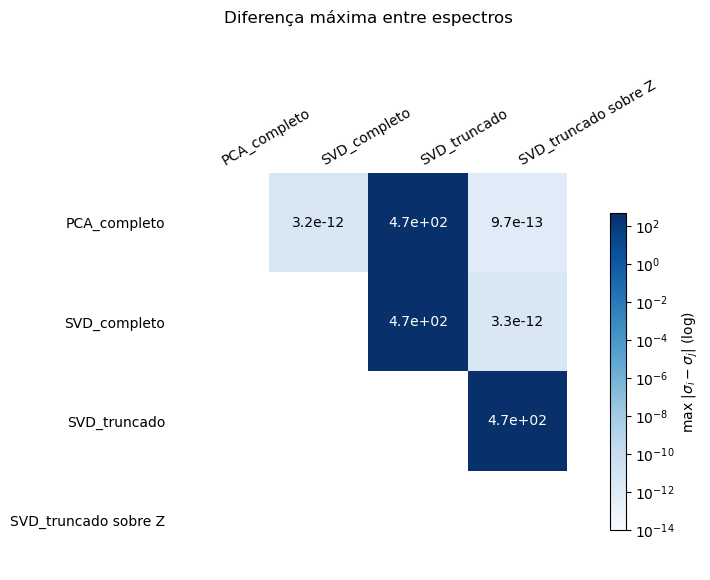

In [147]:
verifica([PCA_completo, SVD_completo, SVD_truncado,
        ('SVD_truncado sobre Z', lambda X, a, info=None: SVD_truncado(padroniza(_como_matriz(X)[0]), a, info=info))],
       0.8);


Os resultados acima demonstram que o SVD truncado é um bom substituto para o SVD completo ou PCA. 

Primeiramente, o gráfico "Diferença máxima entre espectros" explicita que os métodos PCA, SVD completo e SVD truncado (aplicado sobre a matriz normalizada) trabalharam sobre a mesma matriz. Lê-se esse gráfico como "O valor numérico em cada célula é a diferença entre a matriz usada pelo método da linha $i$ e pelo método da coluna $j$ — dada pela distância de Frobenius". Valores abaixo da diagonal principal são suprimidos, pois a matriz é simétrica, e a própria diagonal principal, porque compara matrizes identicas.

A célula (1,2) mostra que a matriz usada no PCA e a usada no SVD completo teve uma distância de aproximadamente zero (só não exatamente por erro de ponto flutuante). E da mesma forma, o método SVD truncado sobre Z utilizou a mesma matriz que PCA (1,4) e SVD completo (2,4). Mas, no caso do SVD truncado (aplicado sobre a matriz esparsa), fica claro que a matriz de entrada é diferente dos demais métodos, visto nas células (1,3) e (2,3).

Essa diferença é reforçãda analisando os gráficos $\sigma_k \times k$. Os três algoritimos produzem a mesma curva, mas o SVD truncado produz uma curva diferente. Mesmo assim, o $k$ encontrado é aproximadamente o mesmo.

Finalmente, visto que os resultados obtidos comportam-se exatamente como estudado no decorrer da disciplina, é seguro afirmar que o ferramental disponível na bibliteca `sklearn` está sendo usado corretamente.

In [ ]:
#@title Aplica o SVD truncado sobre X
reduz_dim = SVD_truncado

X_desc_k, k_desc = reduz_dim(X_desc, alpha=0.6)
print(f'X_desc {X_desc.shape} -> X_desc_k {X_desc_k.shape}, k = {k_desc}')

X_desc (1000, 16915) -> X_desc_k (1000, 452), k = 452


In [ ]:
from sklearn.cluster import KMeans

# Fornecendo os parâmetros do modelo
kmeans = KMeans(n_clusters = 3)

# ajustando o modelo
kmeans.fit(blobs)

# obtendo o identificador de grupo de cada ponto
y_kmeans = kmeans.predict(blobs)

# cada ponto é mapeado para um número, correspondente ao cluster
# ao qual foi associado
y_kmeans